# 07 · Wards, not watersheds
**Question.** Within which units is drying homogeneous: hydrological (DEM catchments), landscape (label-free
regions/communities) or survey (wards)?

**Method.** ICC(1) of drying for each partition against 200 randomly shifted square grids with the same number of
units; landscape homogeneity of each partition; pair concordance; upslope/downslope test; flow-path covariates;
three-way variation partitioning (`src/catchment_analysis.py`, `src/unsupervised.py`, `src/drivers_analysis.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

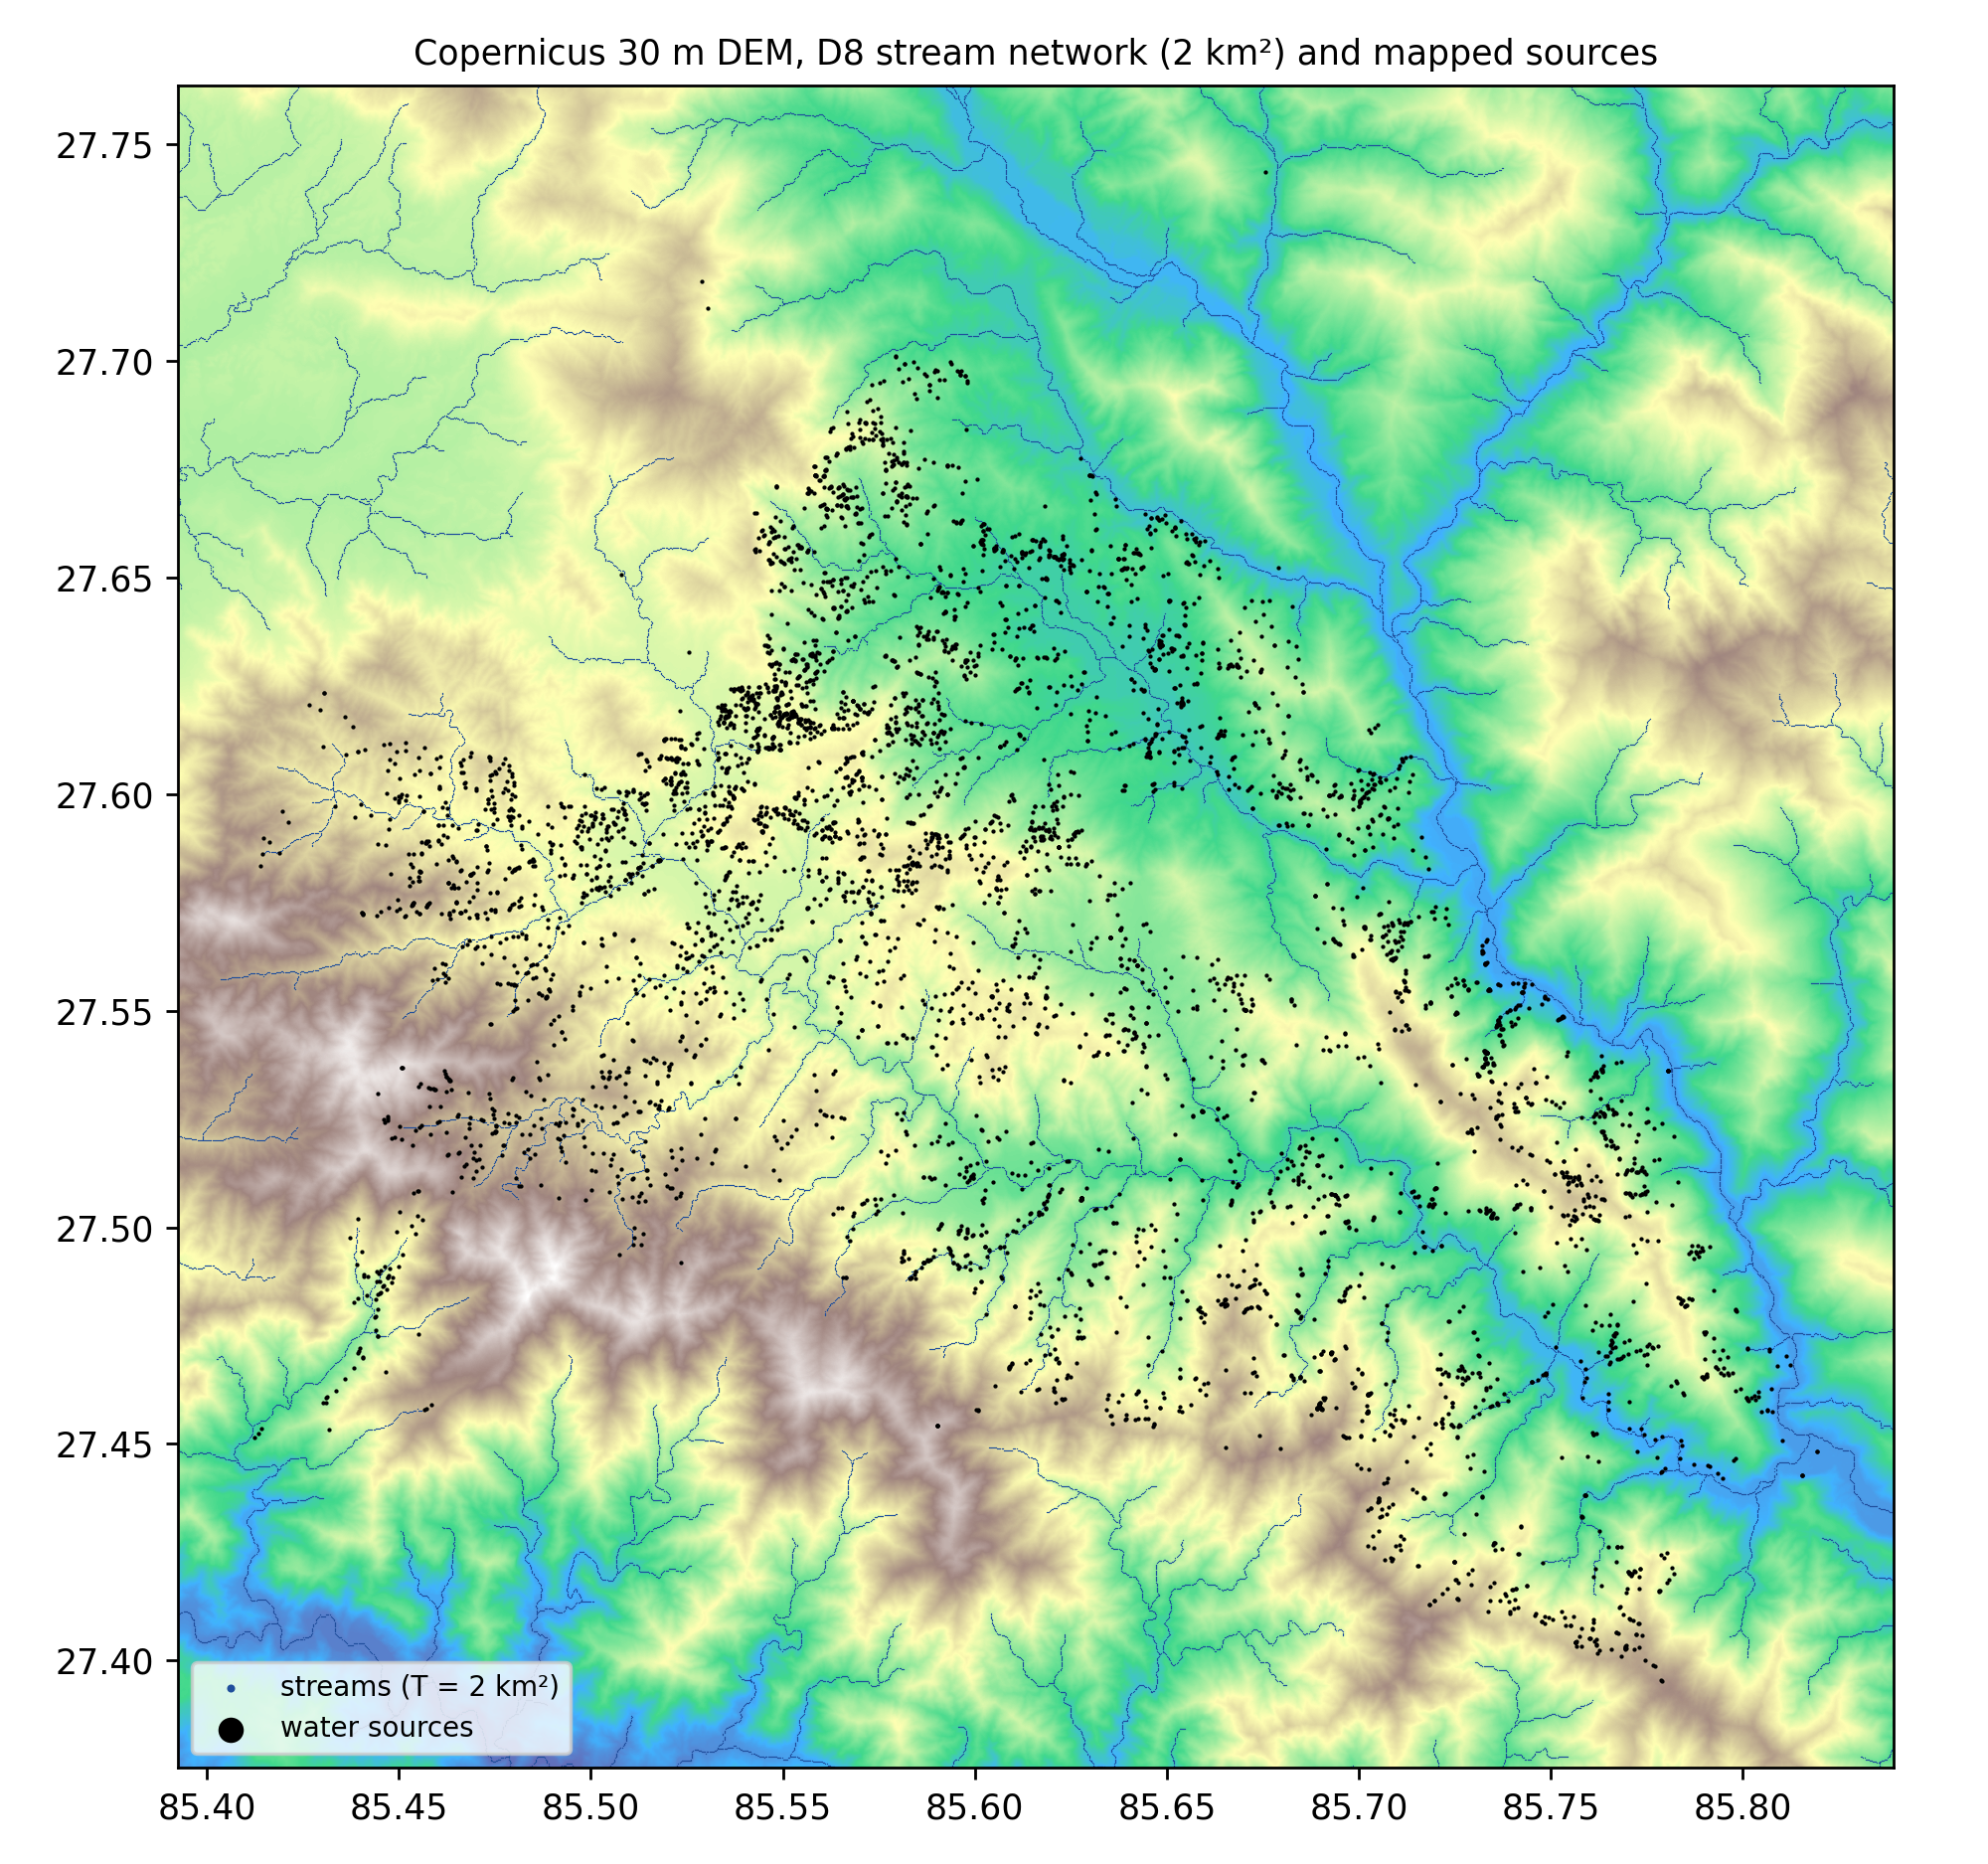

,unit,n_units,mean_sources_per_unit,icc,grid_cell_km,grid_icc_mean,grid_icc_q025,grid_icc_q975,p_above_grid,grid_units_mean
0,catchment T=0.5 km2,619,9.1906,0.1613,1.0154,0.1851,0.1692,0.2001,1.0000,615.850
1,catchment T=2 km2,176,32.3239,0.1221,2.1656,0.1255,0.1158,0.1349,0.7264,176.360
2,catchment T=10 km2,52,109.4038,0.0882,4.5345,0.0880,0.0732,0.0995,0.5025,53.425
3,ward,75,75.8533,0.1318,3.5629,0.0997,0.0921,0.1059,0.0050,78.135
4,municipality,7,812.7143,0.0671,19.3467,0.0439,0.0305,0.0585,0.0050,7.390


In [2]:
fig("hydro_gis_network.png", 600); display(table("ca_unit_icc.csv"))

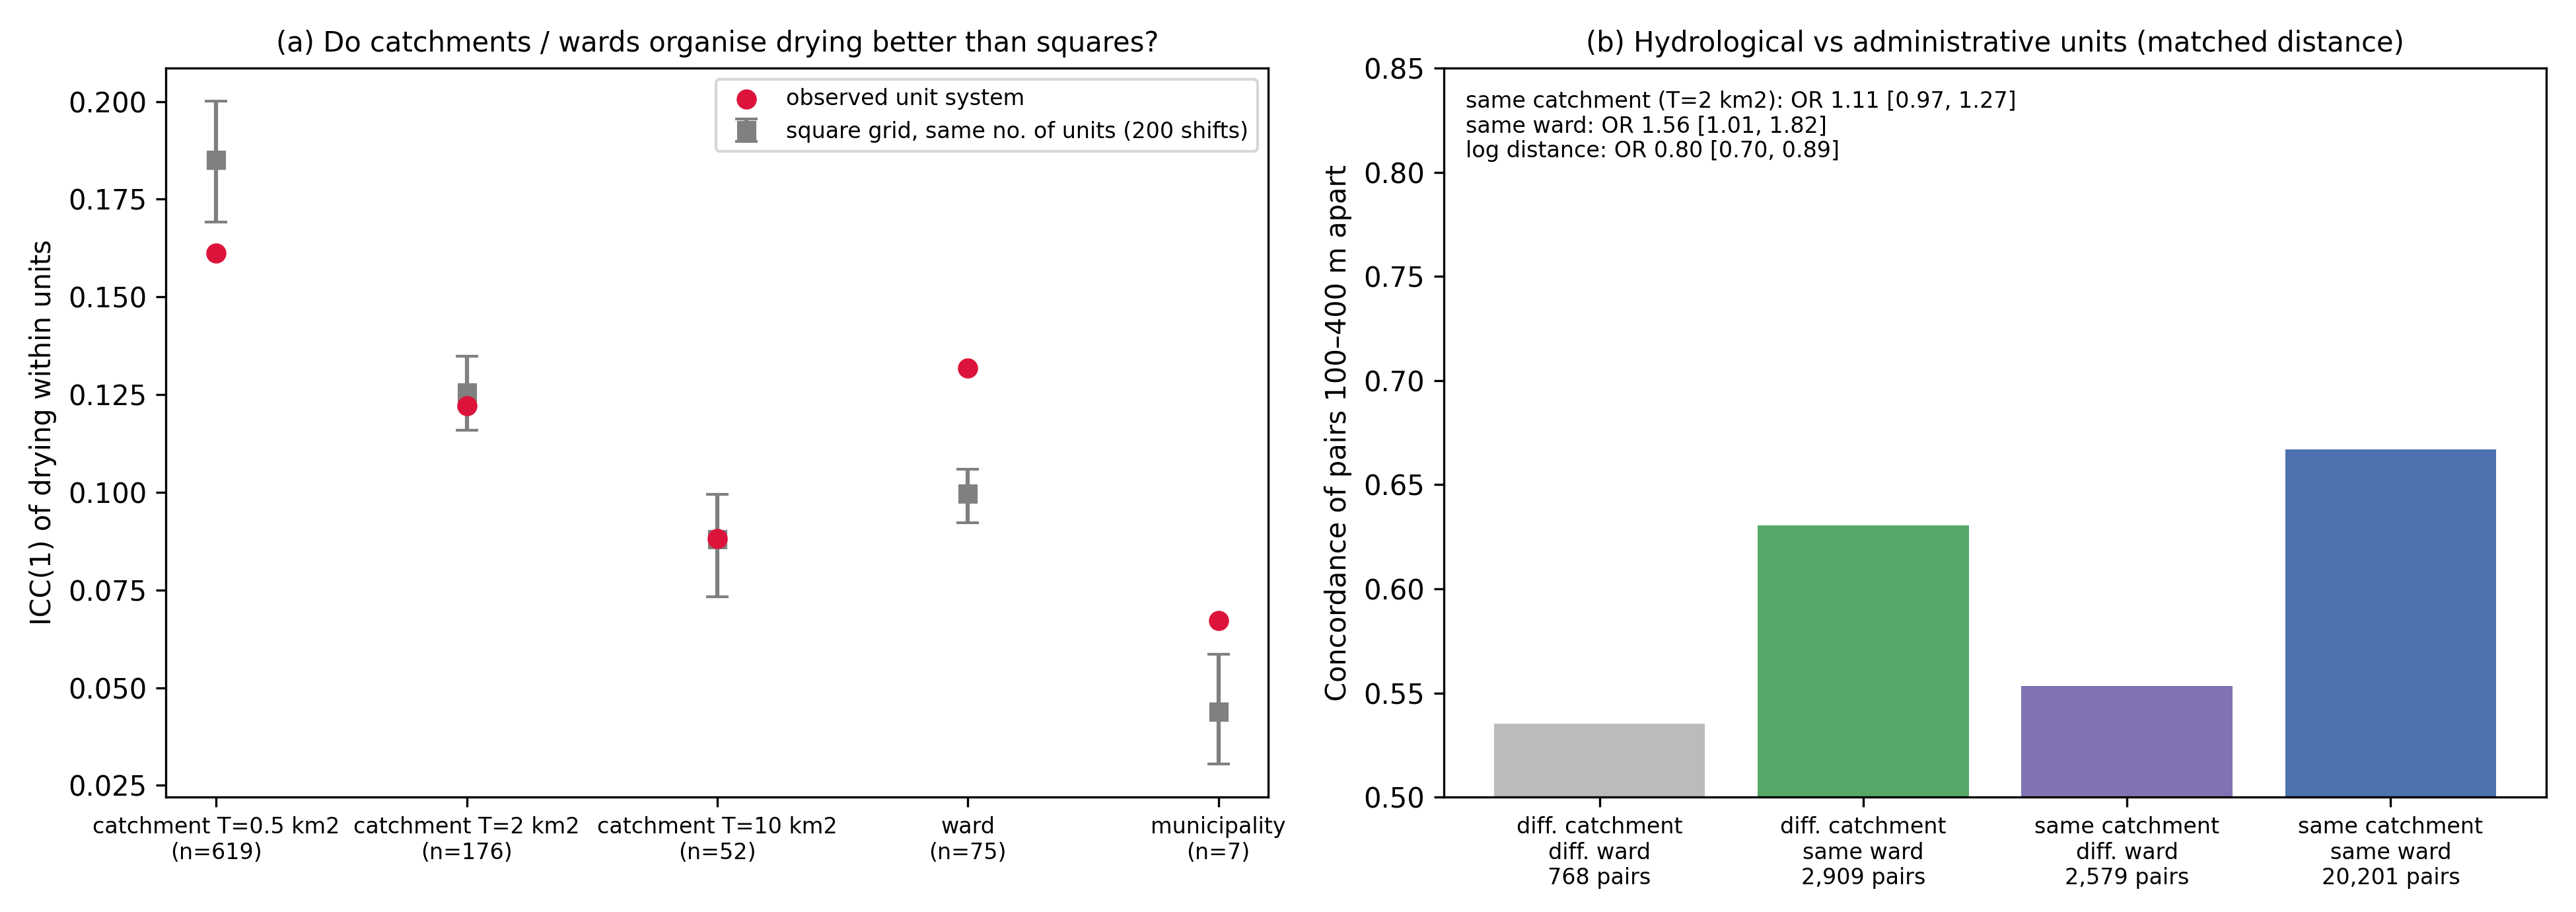

In [3]:
fig("ca_catchment_units.png")

## Label-free regionalisations vs wards

In [4]:
table("un_regionalisation.csv")

,partition,n_units,mean_sources_per_unit,env_r2,icc_drying,grid_cell_km,grid_icc_mean,grid_icc_q025,grid_icc_q975,p_above_grid,ari_with_ward,nmi_with_ward,grid_env_r2_mean,grid_ari_with_ward_mean,louvain_resolution,louvain_modularity
0,ward (survey unit),75,75.8533,0.5222,0.1318,3.5629,0.0994,0.0929,0.1063,0.005,1.0000,1.0000,0.5025,0.4102,NaN,NaN
1,DEM catchment T=2 km²,176,32.3239,0.5672,0.1221,2.1656,0.1263,0.1155,0.1352,0.801,0.4338,0.7959,0.5959,0.4281,NaN,NaN
2,municipality,7,812.7143,0.2938,0.0671,19.3467,0.0434,0.0290,0.0557,0.005,0.1528,0.6162,0.2116,0.0550,NaN,NaN
3,landscape region (n=75),75,75.8533,0.6482,0.1132,3.5629,0.0992,0.0922,0.1057,0.005,0.3705,0.7566,0.5056,0.4118,NaN,NaN
4,landscape region (n=176),176,32.3239,0.7351,0.1529,2.1656,0.1251,0.1144,0.1353,0.005,0.3893,0.7776,0.5945,0.4258,NaN,NaN
5,Louvain landscape-similarity graph,94,60.5213,0.5949,0.1319,3.1650,0.1057,0.0911,0.1189,0.005,0.5035,0.8121,0.5230,0.4308,0.5,0.9789


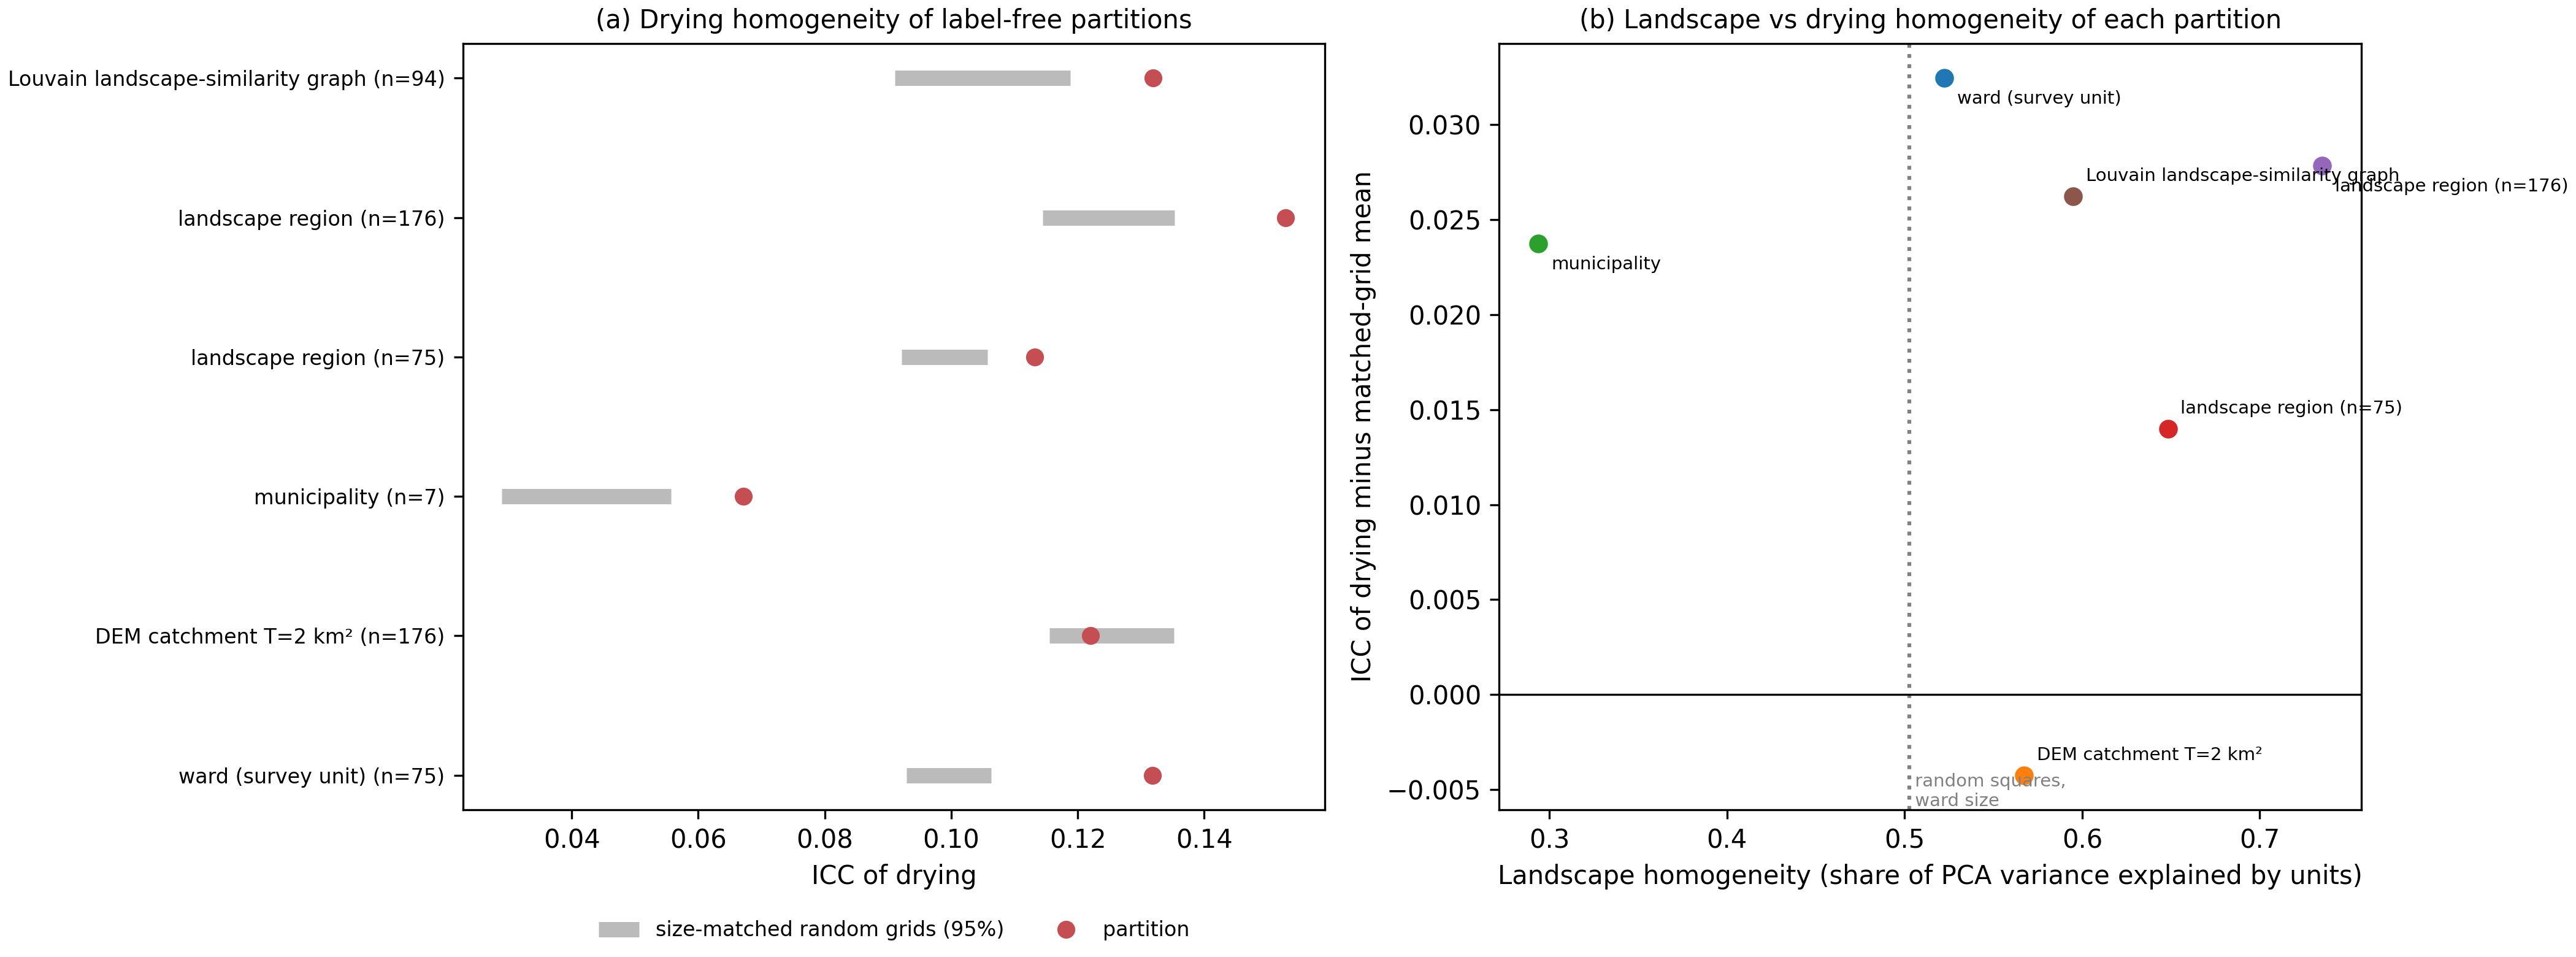

In [5]:
fig("un_regionalisation.png")

## Pairs, directions, flow paths

In [6]:
display(table("sa_ward_concordance.csv")); display(table("ca_pair_concordance_logit.csv"))
display(table("sa_directional_test.csv")); table("ca_flowpath_logit.csv")

,distance_band_m,n_same_ward_pairs,n_diff_ward_pairs,concordance_same_ward,concordance_diff_ward,difference,ci_low,ci_high,mean_distance_same,mean_distance_diff
0,0-100,4890,346,0.7532,0.6243,0.1289,0.0020,0.1874,47.6460,35.5000
1,100-200,6027,526,0.6944,0.5722,0.1221,-0.0488,0.1569,153.1259,155.2751
2,200-400,17083,2821,0.6512,0.5448,0.1064,0.0019,0.1469,304.2753,314.5372


,term,log_odds,ci_low,ci_high,odds_ratio
0,same catchment (T=2 km2),0.1074,-0.0350,0.2364,1.1134
1,same ward,0.4438,0.0094,0.5975,1.5586
2,log distance,-0.2267,-0.3546,-0.1155,0.7971


,quantity,value
0,n sources with up- and downslope neighbours,2961.0000
1,P(dried | all upslope nbrs dried),0.5023
2,P(dried | all downslope nbrs dried),0.5210
3,P(dried | no upslope nbr dried),0.1365
4,P(dried | no downslope nbr dried),0.1507
5,beta_up (std),0.5684
6,beta_down (std),0.5069
7,beta_up - beta_down,0.0615
8,permutation p (two-sided),0.4060
9,null 95% interval low,-0.1392


,term,coef_per_sd,ci_low,ci_high,odds_ratio_per_sd,ci_excludes_zero,model
0,log_flowlen_T2,0.2181,0.0722,0.3724,1.2438,True,drying ~ flow-path
1,strahler_T2p0,0.1857,0.0016,0.3196,1.2041,True,drying ~ flow-path
2,log_contrib_area,-0.2739,-0.3628,-0.1739,0.7604,True,drying ~ flow-path
3,log_flowlen_T2,-0.0515,-0.2000,0.1227,0.9498,False,drying ~ flow-path + environment (no lat/lon)
4,strahler_T2p0,0.1233,-0.0127,0.2212,1.1312,False,drying ~ flow-path + environment (no lat/lon)
5,log_contrib_area,-0.0998,-0.1876,0.0038,0.9051,False,drying ~ flow-path + environment (no lat/lon)


## Three-way variation partitioning

In [7]:
display(table("dr_three_way_partition.csv")); table("dr_three_way_r2.csv")

,fraction,adj_pseudo_r2
0,environment only,0.0498
1,space only,-0.0015
2,ward only,0.0185
3,environment & space,0.0111
4,space & ward,0.0356
5,environment & ward,0.0100
6,all three,0.0415
7,unexplained,0.8350


,E,S,W,ES,EW,SW,ESW
0,0.1124,0.0866,0.1057,0.1464,0.1665,0.1152,0.165


## Explore: ICC of any partition against matched grids

In [8]:
from src.catchment_analysis import icc1, matched_grid_null
from src.graph_builder import load_master, coords_to_metric
df = load_master(); xy = coords_to_metric(df.latitude.to_numpy(), df.longitude.to_numpy()); y = df.target_dried.to_numpy().astype(float)
part = (df.municipality.astype(str) + "_" + df.ward.astype(str)).to_numpy()   # change me
cell, null, _ = matched_grid_null(xy, y, len(np.unique(part)), n_shift=50)
print(f"ICC = {icc1(y, part):.3f}; matched grids (cell {cell/1000:.1f} km): {np.quantile(null, .025):.3f}-{np.quantile(null, .975):.3f}")

ICC = 0.132; matched grids (cell 3.6 km): 0.092-0.105
